# BYD Stock Analysis

Ticker: **BYDDY**, the U.S. OTC-traded depositary receipt, quoted in USD.
Requested period: January 1–October 11, 2026; download end October 12 is exclusive.
Prices are adjusted because `auto_adjust=True` is used.

**Research question:** How did BYDDY perform, and is its largest daily decline
consistent with concerns following BYD's January vehicle-sales announcement?

Install the packages using the README before running this notebook.


In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

print("BYD analysis setup successful!")

BYD analysis setup successful!


In [2]:
TICKER = "BYDDY"
START_DATE = "2026-01-01"
END_DATE = "2026-10-12"

byd = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

if byd.empty:
    raise ValueError(
        "No data downloaded. Check the ticker and internet connection."
    )

if isinstance(byd.columns, pd.MultiIndex):
    byd = byd.xs(TICKER, axis=1, level="Ticker")

byd = byd.sort_index()

print("First trading date:", byd.index.min().date())
print("Last trading date:", byd.index.max().date())
print("Number of rows:", len(byd))

display(byd.head())

First trading date: 2026-01-02
Last trading date: 2026-10-09
Number of rows: 194


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,12.698576,12.738383,12.579154,12.628912,2580800
2026-01-05,12.409972,12.409972,12.191031,12.400020,2430200
2026-01-06,12.549297,12.698576,12.549297,12.688624,1485500
2026-01-07,12.041754,12.280598,12.041754,12.250743,2219600
2026-01-08,12.131319,12.161175,12.011897,12.041753,808800


In [3]:
print("Columns:", byd.columns.tolist())

print("\nData types:")
print(byd.dtypes)

print("\nMissing values:")
print(byd.isna().sum())

print("\nDuplicate dates:", byd.index.duplicated().sum())

Columns: ['Close', 'High', 'Low', 'Open', 'Volume']

Data types:
Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Missing values:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Duplicate dates: 0


In [4]:
# Calculate daily percentage returns
byd["Daily Return"] = byd["Close"].pct_change(fill_method=None) * 100

# Calculate descriptive statistics
print("BYD Daily Return Statistics (%)")
print(byd["Daily Return"].describe())

print("\nBYD Closing Price Statistics ($)")
print(byd["Close"].describe())

BYD Daily Return Statistics (%)
count    193.000000
mean      -0.114604
std        2.382061
min       -6.548100
25%       -1.470592
50%       -0.401926
75%        1.221504
max        8.061897
Name: Daily Return, dtype: float64

BYD Closing Price Statistics ($)
count    194.000000
mean      11.745836
std        1.194431
min        9.270000
25%       11.015000
50%       11.781502
75%       12.653793
max       14.280923
Name: Close, dtype: float64


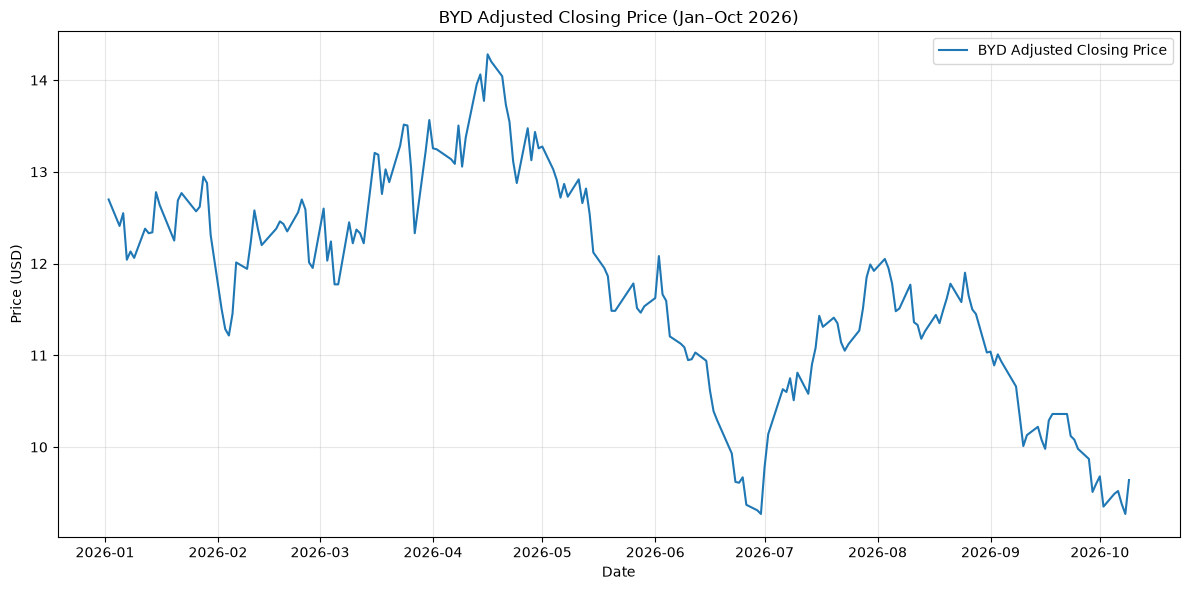

In [5]:
# Plot BYD's adjusted closing price over time
plt.figure(figsize=(12, 6))

plt.plot(
    byd.index,
    byd["Close"],
    label="BYD Adjusted Closing Price"
)

plt.title("BYD Adjusted Closing Price (Jan–Oct 2026)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Figure caption:** BYDDY ended the study period down 24.09%, placing the February sales-news decline within a wider loss rather than explaining the whole trend with one event.


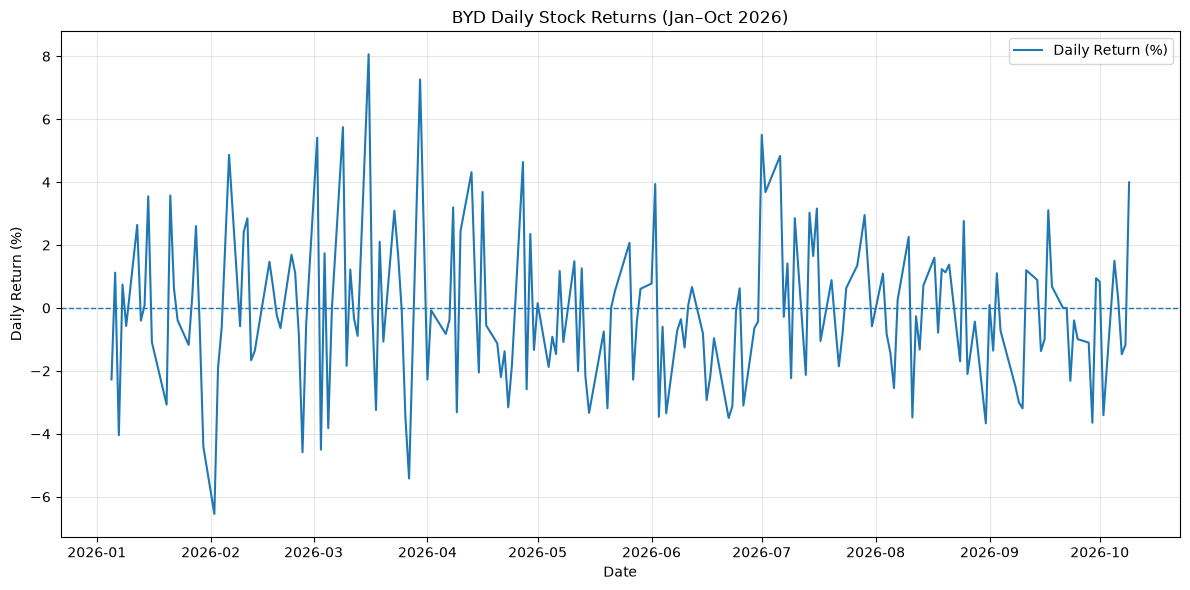

In [6]:
# Plot BYD's daily percentage returns
plt.figure(figsize=(12, 6))

plt.plot(
    byd.index,
    byd["Daily Return"],
    label="Daily Return (%)"
)

plt.axhline(y=0, linestyle="--", linewidth=1)
plt.title("BYD Daily Stock Returns (Jan–Oct 2026)")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Figure caption:** BYDDY's daily-return chart highlights February 2 at -6.55%, its largest daily decline, motivating investigation of the preceding vehicle-sales news.


In [7]:
# Summarize BYD's stock performance
first_close = byd["Close"].iloc[0]
last_close = byd["Close"].iloc[-1]

total_return = (last_close / first_close - 1) * 100
best_day = byd["Daily Return"].idxmax()
worst_day = byd["Daily Return"].idxmin()

print("BYD Stock Performance Summary")
print("-----------------------------")
print(f"First adjusted close: ${first_close:.2f}")
print(f"Last adjusted close: ${last_close:.2f}")
print(f"Total price return: {total_return:.2f}%")
print(f"Best day: {best_day.date()} ({byd.loc[best_day, 'Daily Return']:.2f}%)")
print(f"Worst day: {worst_day.date()} ({byd.loc[worst_day, 'Daily Return']:.2f}%)")

BYD Stock Performance Summary
-----------------------------
First adjusted close: $12.70
Last adjusted close: $9.64
Total price return: -24.09%
Best day: 2026-03-16 (8.06%)
Worst day: 2026-02-02 (-6.55%)


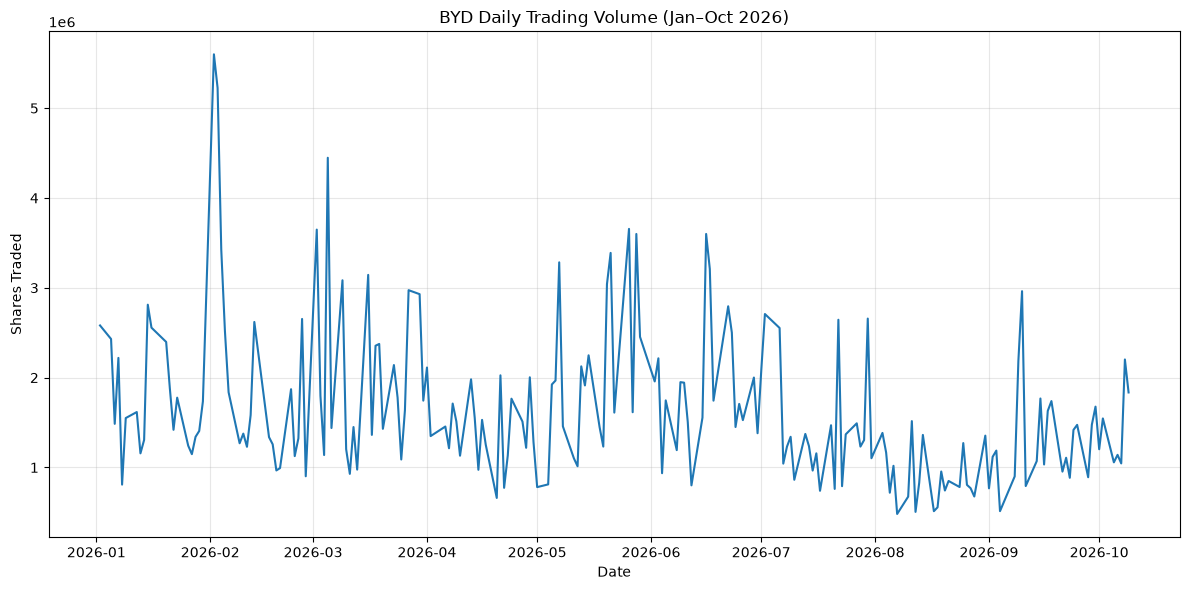

In [8]:
# Plot BYD daily trading volume
plt.figure(figsize=(12, 6))

plt.plot(byd.index, byd["Volume"])

plt.title("BYD Daily Trading Volume (Jan–Oct 2026)")
plt.xlabel("Date")
plt.ylabel("Shares Traded")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Figure caption:** The volume chart identifies February 2 as the highest-volume day at 5,599,500 shares, showing unusually active trading alongside the decline investigated after sales news.


In [9]:
# Find the day with the highest trading volume
highest_volume_date = byd["Volume"].idxmax()

print("BYD Highest Trading Volume")
print("--------------------------")
print("Date:", highest_volume_date.date())
print("Volume:", f"{byd.loc[highest_volume_date, 'Volume']:,}")
print(
    "Daily Return:",
    f"{byd.loc[highest_volume_date, 'Daily Return']:.2f}%"
)
print(
    "Closing Price:",
    f"${byd.loc[highest_volume_date, 'Close']:.2f}"
)

BYD Highest Trading Volume
--------------------------
Date: 2026-02-02
Volume: 5,599,500
Daily Return: -6.55%
Closing Price: $11.50


In [10]:
# Compare highest-volume day with average trading volume
average_volume = byd["Volume"].mean()
highest_volume = byd["Volume"].max()
volume_multiple = highest_volume / average_volume

print("Trading Volume Comparison")
print("-------------------------")
print(f"Average daily volume: {average_volume:,.0f} shares")
print(f"February 2 volume: {highest_volume:,.0f} shares")
print(f"Compared with average: {volume_multiple:.2f} times")

Trading Volume Comparison
-------------------------
Average daily volume: 1,640,636 shares
February 2 volume: 5,599,500 shares
Compared with average: 3.41 times


## Event Window: Five Trading Days Before and After the Largest Decline

The event is selected using the minimum daily return, not the largest absolute
return; BYDDY's largest gain is a separate event. The code reports window
boundaries and the highest and lowest adjusted closes with their dates.


In [11]:
event_date = byd["Daily Return"].idxmin()
event_position = byd.index.get_loc(event_date)
event_window = byd.iloc[max(0, event_position - 5):event_position + 6]
print("Event date:", event_date.date())
print("Window start:", event_window.index.min().date())
print("Window end:", event_window.index.max().date())
print("Previous close (USD):", round(byd["Close"].iloc[event_position - 1], 2))
print("Event close (USD):", round(byd.loc[event_date, "Close"], 2))
print("Lowest adjusted close:", round(event_window["Close"].min(), 2),
      "on", event_window["Close"].idxmin().date())
print("Highest adjusted close:", round(event_window["Close"].max(), 2),
      "on", event_window["Close"].idxmax().date())
display(event_window[["Close", "Daily Return", "Volume"]].round(2))
previous_20_days = byd.iloc[max(0, event_position - 20):event_position]
prior_volume = previous_20_days["Volume"].mean()
print("Prior baseline trading days:", len(previous_20_days))
print("Prior average volume:", round(prior_volume))
print("Event/prior volume ratio:", round(byd.loc[event_date, "Volume"] / prior_volume, 2))


Event date: 2026-02-02
Window start: 2026-01-26
Window end: 2026-02-09
Previous close (USD): 12.31
Event close (USD): 11.5
Lowest adjusted close: 11.22 on 2026-02-04
Highest adjusted close: 12.95 on 2026-01-28


Price,Close,Daily Return,Volume
Date,,,
2026-01-26,12.57,-1.17,1242400
2026-01-27,12.62,0.40,1148000
2026-01-28,12.95,2.60,1340800
2026-01-29,12.88,-0.54,1406200
2026-01-30,12.31,-4.40,1735400
2026-02-02,11.50,-6.55,5599500
2026-02-03,11.29,-1.90,5225400
2026-02-04,11.22,-0.62,3426000
2026-02-05,11.45,2.13,2517000


Prior baseline trading days: 20
Prior average volume: 1743545
Event/prior volume ratio: 3.21


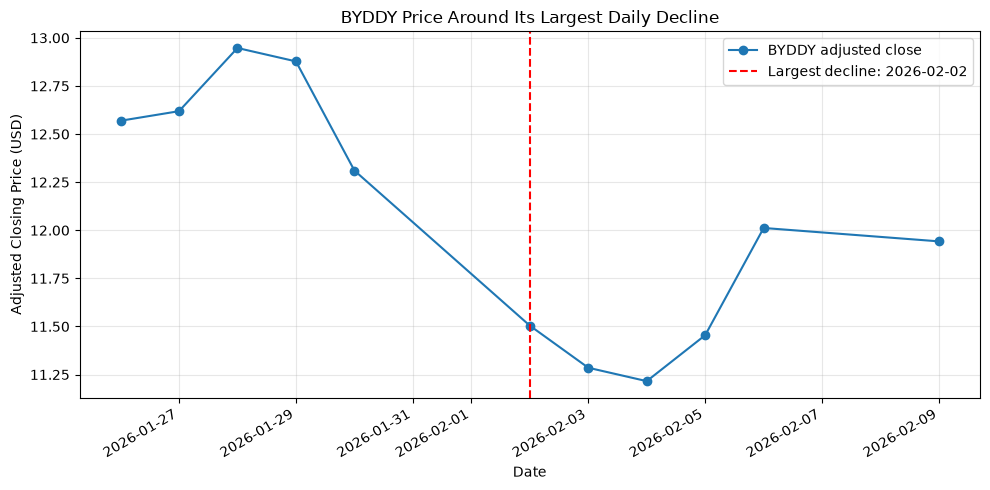

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(event_window.index, event_window["Close"], marker="o", label="BYDDY adjusted close")
ax.axvline(event_date, color="red", linestyle="--", label=f"Largest decline: {event_date:%Y-%m-%d}")
ax.set_title("BYDDY Price Around Its Largest Daily Decline")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Closing Price (USD)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


**Figure caption:** In the January 26–February 9 window, BYDDY reached a high adjusted close of $12.95 on January 28 and a low of $11.22 on February 4, placing the February 2 sales-news decline within its local price path without proving causation.


## Possible Business Explanation and Evidence

On February 2, 2026, BYDDY declined 6.55% and volume reached 5,599,500 shares,
3.41 times the full-period daily average. Reuters reported on February 1 that
BYD's January sales fell 30.1% year over year [1], before the next U.S. session.
This provides a plausible demand-related explanation to investigate.

The daily-return chart identifies the unusually negative day; the volume
chart shows elevated activity; and the event-window table and chart show the
nearby high, low, and subsequent price pattern. Together they are consistent
with a response to sales concerns, but do not establish investor motives or
exclude other company, market, or industry news.

### Source

[1] Reuters. "China's BYD vehicle sales fall for fifth month in a row."
February 1, 2026. Published through Investing.com.
https://ca.investing.com/news/stock-market-news/chinas-byd-vehicle-sales-fall-for-fifth-month-in-a-row-4430774

The article describes BYD's company sales. Its figures are not BYDDY stock
returns; the stock return and volume above come from yfinance/pandas.

## Main Findings and Limitations

- BYDDY's full-period adjusted-price change was -24.09%; the largest daily
  decline was -6.55% on February 2 and the largest gain +8.06% on March 16.
- The February decline coincided with the highest daily volume in the sample,
  supporting further investigation of the preceding sales announcement.
- The full-period 3.41-times volume baseline includes post-event observations.
  The preceding-trading-day baseline printed above is provided separately;
  it uses up to 20 observations, without filling unavailable earlier days.
- News timing and trading activity support a possible explanation, not a
  causal estimate. A market benchmark and additional news checks would be
  needed to isolate the event effect.
- BYDDY is an OTC depositary receipt; liquidity and trading arrangements can
  affect comparisons. The sample is partial-year historical evidence.
- Pairwise return correlations and group comparison charts are in
  [comparison_analysis.ipynb](comparison_analysis.ipynb).


## Event-Window Results

The freshly executed window covers **January 26–February 9, 2026**.
The highest adjusted close was **$12.95 on January 28** and the lowest was
**$11.22 on February 4**. February 2 volume was **3.21 times** the previous
20 trading days' average, compared with **3.41 times** the full-period average.
The two ratios use different denominators and must not be interchanged.
These are observed prices and trading activity, not a causal estimate.
